<a href="https://colab.research.google.com/github/ShubhGuPTA-cmd/ML-experiments/blob/main/Cart_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load Breast Cancer dataset

data = load_breast_cancer()

# Convert dataset into DataFrame

df = pd.DataFrame(data.data, columns=data.feature_names)

# Add target column

df['target'] = data.target

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Display first 5 rows

print("First 5 rows:")
display(df.head())

# Display dataset shape

print("Dataset Shape:", df.shape)

# Display information

print("\nDataset Information:")
df.info()

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# Display target distribution

print("\nTarget Distribution:")
print(df['target'].value_counts())

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Dataset Shape: (569, 31)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-

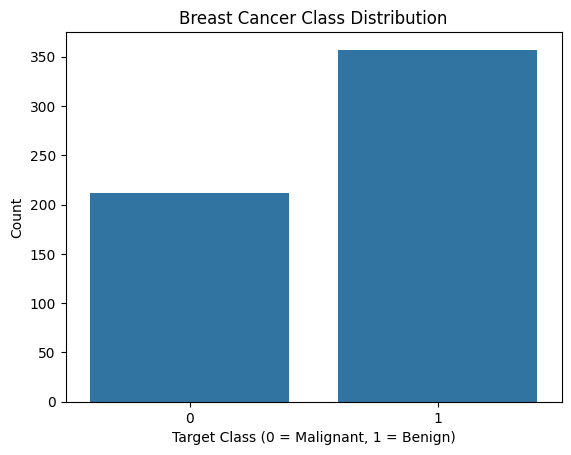

In [ ]:
# Plot target class distribution

sns.countplot(x='target', data=df)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Target Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")
plt.show()

In [ ]:
# Separate input and output variables

X = df.drop('target', axis=1)
y = df['target']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nNumber of Features:", X.shape[1])

Input Features:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [ ]:
# Create CART model

cart_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

# Train the model

cart_model.fit(X_train, y_train)

print("CART Model trained successfully!")

CART Model trained successfully!


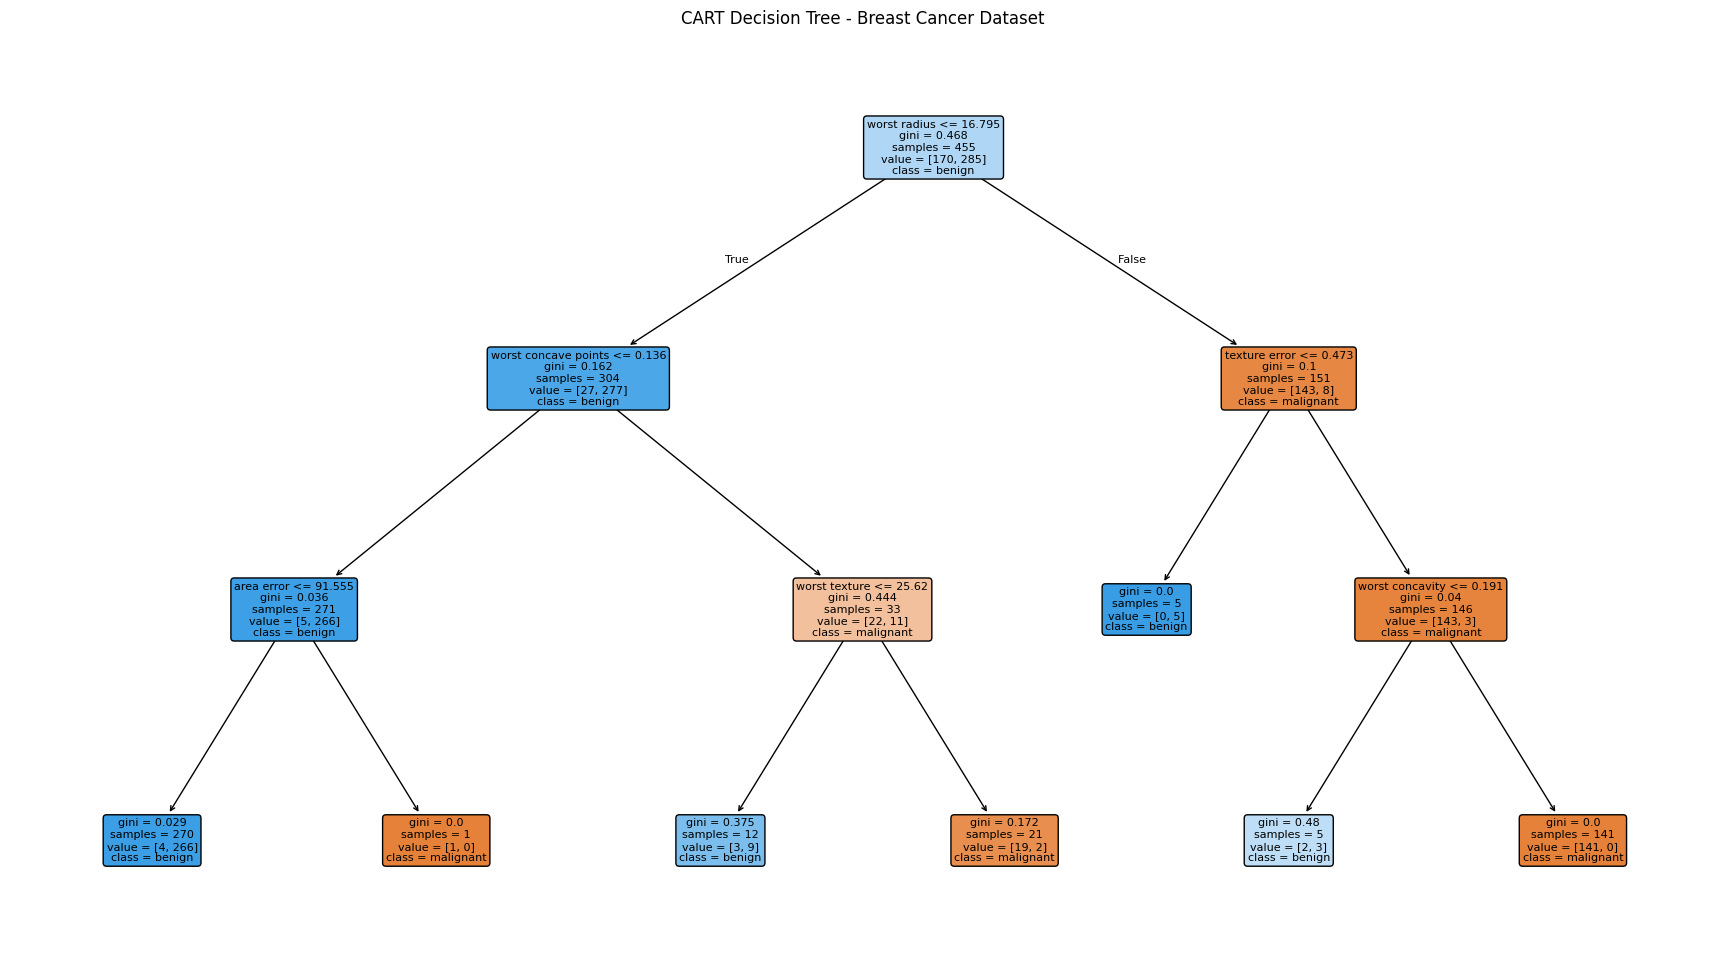

In [ ]:
# Visualize CART decision tree

plt.figure(figsize=(22, 12))

plot_tree(
    cart_model,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree - Breast Cancer Dataset")
plt.show()

In [ ]:
# Predict using test data

y_pred = cart_model.predict(X_test)

print("Actual Values:")
print(y_test.values[:15])

print("\nPredicted Values:")
print(y_pred[:15])

Actual Values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0]

Predicted Values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0]


In [ ]:
# Calculate performance metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, average='weighted')

recall = recall_score(y_test, y_pred, average='weighted')

f1 = f1_score(y_test, y_pred, average='weighted')

# Display results

print("CART Model Performance")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

CART Model Performance
Accuracy : 0.9386
Precision: 0.9384
Recall   : 0.9386
F1 Score : 0.9384


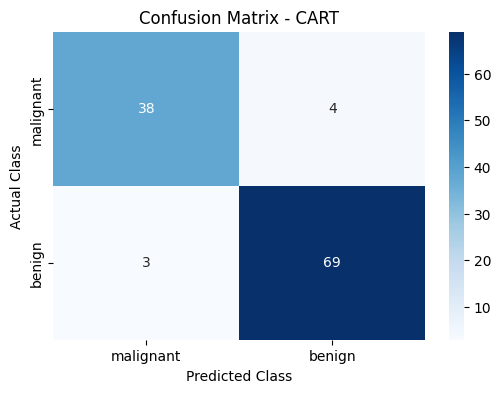

In [ ]:
# Generate confusion matrix

cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - CART")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [ ]:
# Test different tree depths

depths = [1, 2, 3, 4, 5, None]

results = []

for depth in depths:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )

    # Train model

    model.fit(X_train, y_train)

    # Predictions

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Calculate accuracy

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    # Store results

    results.append({
        'Max Depth': str(depth),
        'Training Accuracy': train_accuracy,
        'Testing Accuracy': test_accuracy
    })

# Display comparison table

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.9231,0.9211
1,2,0.9582,0.8947
2,3,0.9758,0.9386
3,4,0.9868,0.9386
4,5,0.9934,0.9211
5,None,1.0000,0.9123


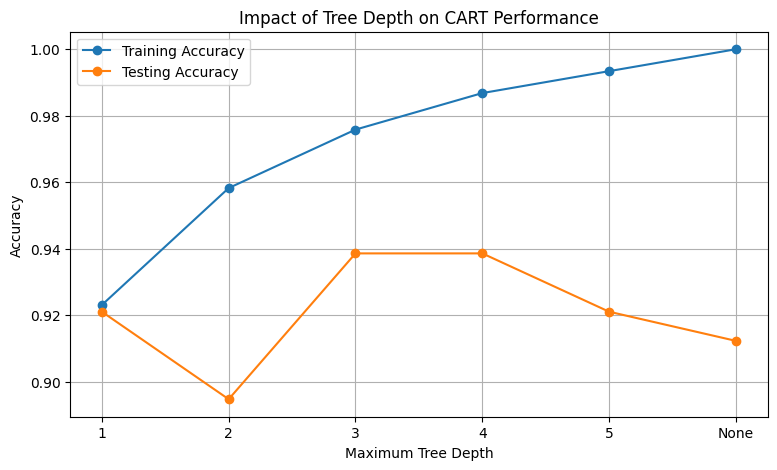

In [ ]:
# Compare training and testing accuracy

plt.figure(figsize=(9, 5))

plt.plot(
    results_df['Max Depth'],
    results_df['Training Accuracy'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    results_df['Max Depth'],
    results_df['Testing Accuracy'],
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Impact of Tree Depth on CART Performance")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Test different tree parameters

parameters = [
    (3, 2, 1),
    (4, 5, 2),
    (5, 10, 4),
    (None, 20, 5)
]

parameter_results = []

for depth, split, leaf in parameters:

    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        min_samples_split=split,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    parameter_results.append({
        'Max Depth': str(depth),
        'Min Samples Split': split,
        'Min Samples Leaf': leaf,
        'Accuracy': accuracy_score(y_test, prediction),
        'Precision': precision_score(
            y_test, prediction, average='weighted'
        ),
        'Recall': recall_score(
            y_test, prediction, average='weighted'
        ),
        'F1 Score': f1_score(
            y_test, prediction, average='weighted'
        )
    })

parameter_df = pd.DataFrame(parameter_results)

display(parameter_df.round(4))

,Max Depth,Min Samples Split,Min Samples Leaf,Accuracy,Precision,Recall,F1 Score
0,3,2,1,0.9386,0.9384,0.9386,0.9384
1,4,5,2,0.9298,0.9311,0.9298,0.9301
2,5,10,4,0.9035,0.9061,0.9035,0.9041
3,None,20,5,0.9386,0.9384,0.9386,0.9384


In [ ]:
# Display classification report

print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [ ]:
# Find the best tree depth

best_result = results_df.loc[
    results_df['Testing Accuracy'].idxmax()
]

print("Best CART Model:")
print("Maximum Depth:", best_result['Max Depth'])
print("Testing Accuracy:", round(
    best_result['Testing Accuracy'], 4
))

Best CART Model:
Maximum Depth: 3
Testing Accuracy: 0.9386
